Install Packages and Set Up the Data

In [1]:
# Install these packages with the command below to run the code
# pip install pandas seaborn matplotlib

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

df = pd.read_csv("../Data/transformed_study_data.csv")

Static Visualization Implementation

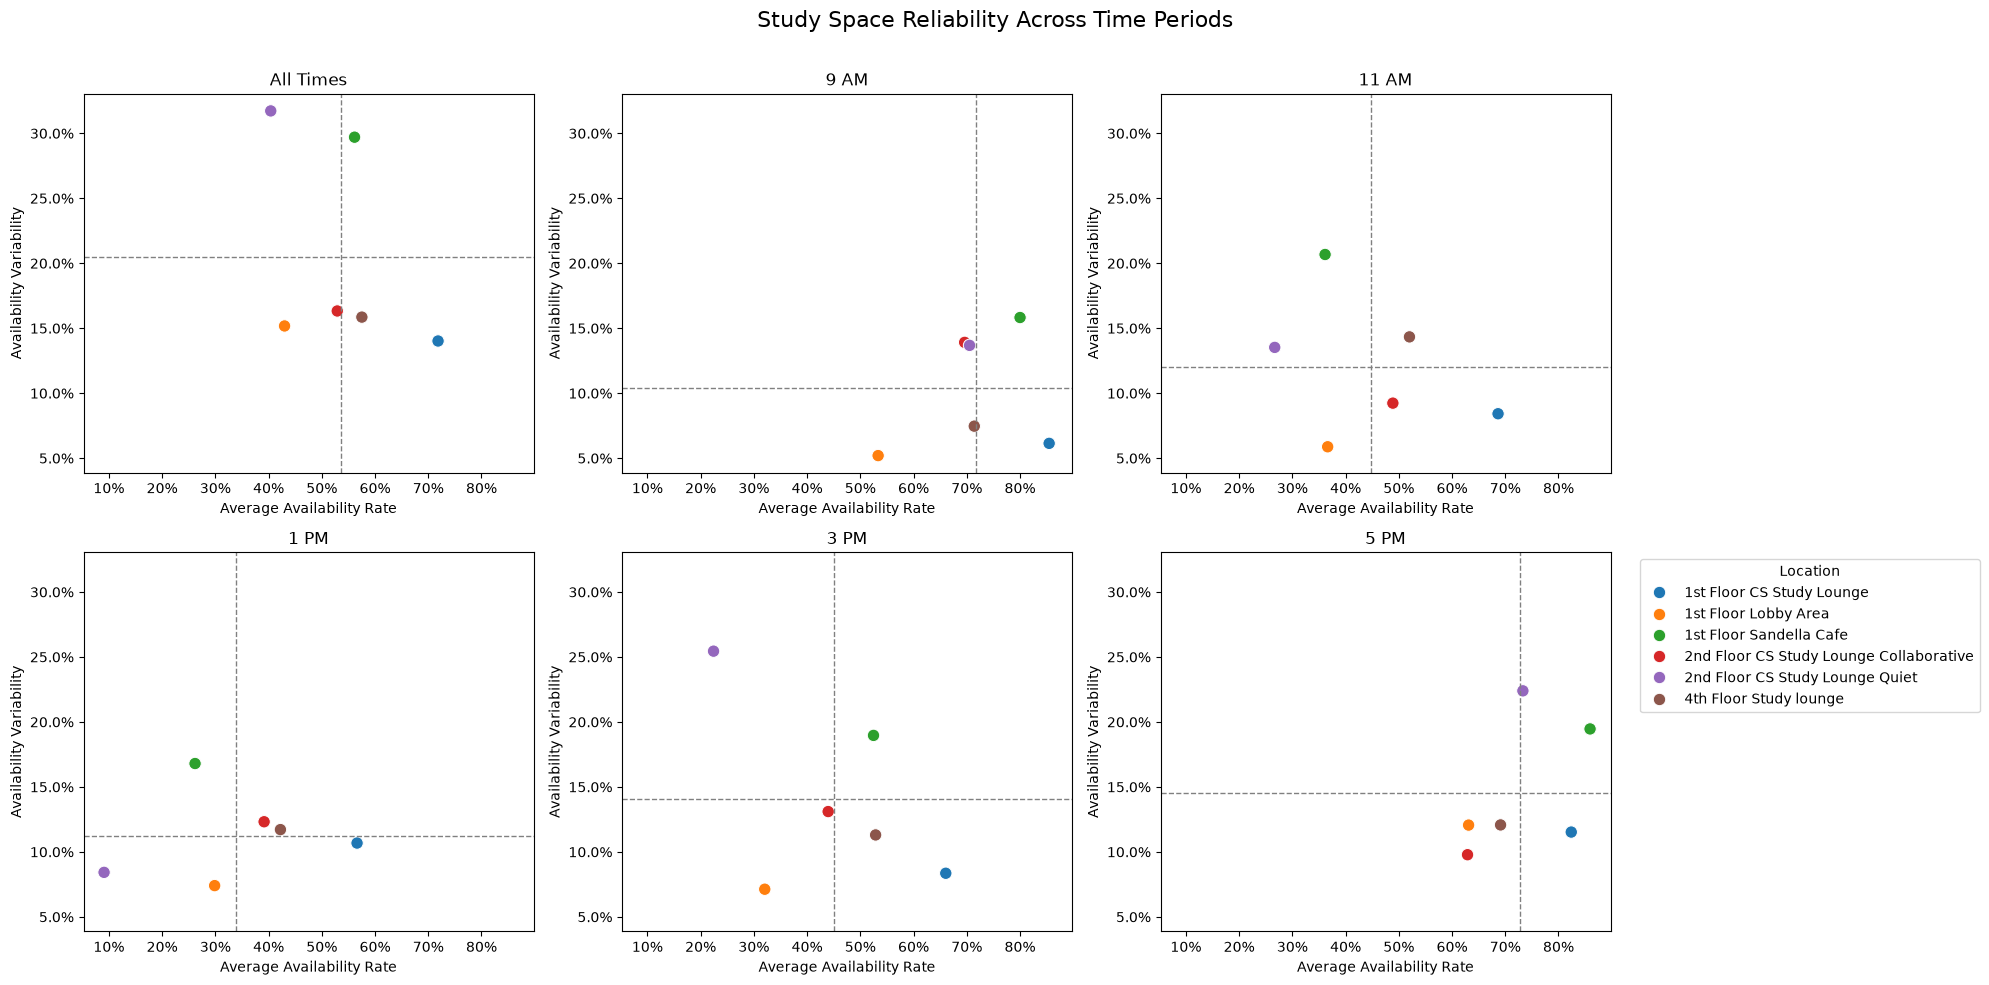

In [2]:
# Ensure time values are treated consistently as strings
df["time"] = df["time"].astype(str)

# Calculate overall reliability metrics across all time periods
all_data = (
    df.groupby("location")
      .agg(
          avg_availability=("availability_rate", "mean"),
          availability_std=("availability_rate", "std"),
          avg_occupancy=("occupancy_rate", "mean"),
          traffic_level=("traffic_level", "first")
      )
      .reset_index()
)


# Calculate reliability metrics for each individual time period
time_summaries = {}

for t in ["9:00", "11:00", "13:00", "15:00", "17:00"]:
    time_summaries[t] = (
        df[df["time"] == t]
        .groupby("location")
        .agg(
            avg_availability=("availability_rate", "mean"),
            availability_std=("availability_rate", "std"),
            avg_occupancy=("occupancy_rate", "mean"),
            traffic_level=("traffic_level", "first")
        )
        .reset_index()
    )


# Create a 2x3 grid of small multiple scatterplots
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(20, 10),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

# Pair each dataset with its corresponding subplot title
plot_data = [
    ("All Times", all_data),
    ("9 AM", time_summaries["9:00"]),
    ("11 AM", time_summaries["11:00"]),
    ("1 PM", time_summaries["13:00"]),
    ("3 PM", time_summaries["15:00"]),
    ("5 PM", time_summaries["17:00"])
]


# Generate a scatterplot for each time period
for ax, (title, data) in zip(axes, plot_data):

    # Compute subplot reference values
    avg_x = data["avg_availability"].mean()
    avg_y = data["availability_std"].mean()

    sns.scatterplot(
        data=data,
        x="avg_availability",
        y="availability_std",
        hue="location",
        s=80,
        ax=ax
    )

    ax.set_title(title, fontsize=12)

    # Add mean reference lines for availability and variability
    ax.axvline(
        avg_x,
        linestyle="--",
        color="gray",
        linewidth=1
    )

    ax.axhline(
        avg_y,
        linestyle="--",
        color="gray",
        linewidth=1
    )

    # Display values as percentages
    ax.xaxis.set_major_formatter(
        ticker.PercentFormatter(1.0)
    )

    ax.yaxis.set_major_formatter(
        ticker.PercentFormatter(1.0)
    )

# Show axis labels and tick labels on every subplot
for ax in axes:
    ax.tick_params(axis="x", labelbottom=True)
    ax.tick_params(axis="y", labelleft=True)

    ax.set_xlabel("Average Availability Rate")
    ax.set_ylabel("Availability Variability")

    ax.xaxis.label.set_visible(True)
    ax.yaxis.label.set_visible(True)


# Remove duplicate legends from the first five plots
for ax in axes[:-1]:
    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Keep one shared legend
axes[-1].legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)


# Add an overall figure title
plt.suptitle(
    "Study Space Reliability Across Time Periods", 
    fontsize=16
)

# Adjust spacing to prevent overlap
plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()

Install Packages

In [3]:
# Install these packages with the commands below to run the code
# pip install plotly
# pip install --upgrade nbformat

import plotly.graph_objects as go

Interactive Visualization Implementation

In [10]:
locations = all_data["location"].tolist()

color_map = {
    "1st Floor CS Study Lounge": "#1f77b4",
    "1st Floor Lobby Area": "#ff7f0e",
    "1st Floor Sandella Cafe": "#2ca02c",
    "2nd Floor CS Study Lounge Collaborative": "#d62728",
    "2nd Floor CS Study Lounge Quiet": "#9467bd",
    "4th Floor Study lounge": "#8c564b"
}

# Average reference lines for each time period
reference_lines = {
    "All Times": (
        all_data["avg_availability"].mean(),
        all_data["availability_std"].mean()
    ),
    "9 AM": (
        time_summaries["9:00"]["avg_availability"].mean(),
        time_summaries["9:00"]["availability_std"].mean()
    ),
    "11 AM": (
        time_summaries["11:00"]["avg_availability"].mean(),
        time_summaries["11:00"]["availability_std"].mean()
    ),
    "1 PM": (
        time_summaries["13:00"]["avg_availability"].mean(),
        time_summaries["13:00"]["availability_std"].mean()
    ),
    "3 PM": (
        time_summaries["15:00"]["avg_availability"].mean(),
        time_summaries["15:00"]["availability_std"].mean()
    ),
    "5 PM": (
        time_summaries["17:00"]["avg_availability"].mean(),
        time_summaries["17:00"]["availability_std"].mean()
    )
}

# Create interactive figure
fig = go.Figure()


# Plot All Times view by default
for location in locations:

    row = all_data[
        all_data["location"] == location
    ].iloc[0]

    fig.add_trace(
        go.Scatter(
            x=[row["avg_availability"]],
            y=[row["availability_std"]],
            mode="markers",
            name=location,
            marker=dict(
                size=8,
                color=color_map[location]
            ),
            customdata=[[
                row["location"]
            ]],
            hovertemplate=
            "<b>%{customdata[0]}</b><br><br>"
            "Average Availability: %{x:.1%}<br>"
            "Availability Variability: %{y:.1%}<br>"
            "<extra></extra>"
        )
    )

# Map each dropdown option to its dataset
dropdown_data = {
    "All Times": all_data,
    "9 AM": time_summaries["9:00"],
    "11 AM": time_summaries["11:00"],
    "1 PM": time_summaries["13:00"],
    "3 PM": time_summaries["15:00"],
    "5 PM": time_summaries["17:00"]
}

# Build dropdown menu options
buttons = []

for label, dataset in dropdown_data.items():

    x_values = []
    y_values = []
    custom_values = []

    for location in locations:

        row = dataset[
            dataset["location"] == location
        ].iloc[0]

        x_values.append(
            row["avg_availability"]
        )

        y_values.append(
            row["availability_std"]
        )

        custom_values.append([
            row["location"]
        ])

    # Retrieve reference line positions
    avg_x, avg_y = reference_lines[label]

    # Add dropdown option
    buttons.append(
        dict(
            label=label,
            method="update",
            args=[
                {
                    "x": [[x] for x in x_values],
                    "y": [[y] for y in y_values],
                    "customdata": [[c] for c in custom_values]
                },
                {
                    "shapes": [
                        dict(
                            type="line",
                            x0=avg_x,
                            x1=avg_x,
                            y0=0,
                            y1=1,
                            yref="paper",
                            line=dict(
                                color="gray",
                                dash="dash",
                                width=1
                            )
                        ),
                        dict(
                            type="line",
                            x0=0,
                            x1=1,
                            xref="paper",
                            y0=avg_y,
                            y1=avg_y,
                            line=dict(
                                color="gray",
                                dash="dash",
                                width=1
                            )
                        )
                    ]
                }
            ]
        )
    )

# Default reference lines for All Times
initial_x, initial_y = reference_lines["All Times"]

# Configure layout and dropdown menu
fig.update_layout(
    title="Study Space Reliability Across Time Periods",

    xaxis_title="Average Availability Rate",
    yaxis_title="Availability Variability",

    legend_title_text="Location",

    updatemenus=[
        dict(
            buttons=buttons,
            direction="down",
            x=0.95,
            y=1.18
        )
    ],

    shapes=[
        dict(
            type="line",
            x0=initial_x,
            x1=initial_x,
            y0=0,
            y1=1,
            yref="paper",
            line=dict(
                color="gray",
                dash="dash",
                width=1
            )
        ),
        dict(
            type="line",
            x0=0,
            x1=1,
            xref="paper",
            y0=initial_y,
            y1=initial_y,
            line=dict(
                color="gray",
                dash="dash",
                width=1
            )
        )
    ]
)

# Format axes and fix ranges
fig.update_xaxes(
    tickformat=".0%",
    range=[0.05, 0.90]
)
fig.update_yaxes(
    tickformat=".0%",
    range=[0.00, 0.35]
)

# Display interactive visualization
fig.show()

In [5]:
time_summaries["9:00"]

,location,avg_availability,availability_std,avg_occupancy,traffic_level
0,1st Floor CS Study Lounge,0.854800,0.061421,0.145200,Low Traffic
1,1st Floor Lobby Area,0.533533,0.051998,0.466467,High Traffic
2,1st Floor Sandella Cafe,0.800133,0.158256,0.199867,High Traffic
3,2nd Floor CS Study Lounge Collaborative,0.696067,0.139133,0.303933,Low Traffic
4,2nd Floor CS Study Lounge Quiet,0.705267,0.136821,0.294733,Low Traffic
5,4th Floor Study lounge,0.714133,0.074660,0.285867,Low Traffic


In [6]:
time_summaries["11:00"]

,location,avg_availability,availability_std,avg_occupancy,traffic_level
0,1st Floor CS Study Lounge,0.686467,0.084211,0.313533,Low Traffic
1,1st Floor Lobby Area,0.366400,0.058797,0.633600,High Traffic
2,1st Floor Sandella Cafe,0.361533,0.206759,0.638467,High Traffic
3,2nd Floor CS Study Lounge Collaborative,0.488867,0.092371,0.511133,Low Traffic
4,2nd Floor CS Study Lounge Quiet,0.266933,0.135267,0.733067,Low Traffic
5,4th Floor Study lounge,0.520067,0.143362,0.479933,Low Traffic


In [7]:
time_summaries["13:00"]

,location,avg_availability,availability_std,avg_occupancy,traffic_level
0,1st Floor CS Study Lounge,0.566267,0.106790,0.433733,Low Traffic
1,1st Floor Lobby Area,0.298733,0.074044,0.701267,High Traffic
2,1st Floor Sandella Cafe,0.261933,0.167991,0.738067,High Traffic
3,2nd Floor CS Study Lounge Collaborative,0.391667,0.123181,0.608333,Low Traffic
4,2nd Floor CS Study Lounge Quiet,0.091000,0.084250,0.909000,Low Traffic
5,4th Floor Study lounge,0.422333,0.117158,0.577667,Low Traffic


In [8]:
time_summaries["15:00"]

,location,avg_availability,availability_std,avg_occupancy,traffic_level
0,1st Floor CS Study Lounge,0.660600,0.083558,0.339400,Low Traffic
1,1st Floor Lobby Area,0.320533,0.071272,0.679467,High Traffic
2,1st Floor Sandella Cafe,0.524867,0.189636,0.475133,High Traffic
3,2nd Floor CS Study Lounge Collaborative,0.439667,0.131030,0.560333,Low Traffic
4,2nd Floor CS Study Lounge Quiet,0.224333,0.254461,0.775667,Low Traffic
5,4th Floor Study lounge,0.528800,0.113039,0.471200,Low Traffic


In [9]:
time_summaries["17:00"]

,location,avg_availability,availability_std,avg_occupancy,traffic_level
0,1st Floor CS Study Lounge,0.824000,0.115251,0.176000,Low Traffic
1,1st Floor Lobby Area,0.631133,0.120620,0.368867,High Traffic
2,1st Floor Sandella Cafe,0.859333,0.194616,0.140667,High Traffic
3,2nd Floor CS Study Lounge Collaborative,0.629133,0.097824,0.370867,Low Traffic
4,2nd Floor CS Study Lounge Quiet,0.733133,0.223934,0.266867,Low Traffic
5,4th Floor Study lounge,0.691200,0.120749,0.308800,Low Traffic
